# WEEK 3 — LAB 1B: Convolution, Correlation and Difference Equations

**Unit:** Unit 1 — Signals and Systems

**Name:** Tedy Deodatus Mlengera

**Registration Number:** 230242409456

**Date:** 25 November 2026

**Group:** 08



## Pre-lab Preparation

### Question (a): Convolution by Hand

Given:

\[
x(n)=\{1,-1,2\}
\]

\[
h(n)=\{2,1,0,1\}
\]

Using linear convolution:

\[
y(n)=x(n)*h(n)
\]

The result is:

\[
\boxed{y(n)=\{2,-1,3,3,-1,2\}}
\]

The output has six samples because:

\[
N=L+M-1=3+4-1=6
\]

### Question (b): Time Invariance

Given:

\[
y(n)=nx(n)
\]

This system is not time-invariant.

For an input \(x(n)\), the output is:

\[
y(n)=nx(n)
\]

If the input is delayed by \(n_0\), the output becomes:

\[
T\{x(n-n_0)\}=n x(n-n_0)
\]

However, delaying the original output gives:

\[
y(n-n_0)=(n-n_0)x(n-n_0)
\]

These two expressions are not equal in general.

Therefore, the system is time-varying (not time-invariant).

## Task 3.1 — Convolution from the Definition

### Objective
To implement linear convolution using its mathematical definition and verify the results using NumPy's `np.convolve()` function.

### Procedure
1. Implement convolution using nested for loops.
2. Compare the result with NumPy convolution.
3. Verify the pre-lab convolution answer.
4. Compare execution time for two random sequences of length 2000.

In [1]:
import numpy as np
import time

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y


# Test convolution
x = [1, 2, 3, 1]
h = [1, 1, 1]

print("Convolution using our function:")
print(conv(x, h))

print("\nConvolution using np.convolve:")
print(np.convolve(x, h))


# Verify pre-lab answer
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]

print("\nPre-lab convolution using our function:")
print(conv(x_pre, h_pre))

print("\nPre-lab convolution using np.convolve:")
print(np.convolve(x_pre, h_pre))


# Timing comparison
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)

start = time.perf_counter()
conv(x_random, h_random)
loop_time = time.perf_counter() - start

start = time.perf_counter()
np.convolve(x_random, h_random)
numpy_time = time.perf_counter() - start

print("\nTiming comparison:")
print(f"Our convolution function: {loop_time:.6f} seconds")
print(f"NumPy convolution: {numpy_time:.6f} seconds")

Convolution using our function:
[1. 3. 6. 6. 4. 1.]

Convolution using np.convolve:
[1 3 6 6 4 1]

Pre-lab convolution using our function:
[ 2. -1.  3.  3. -1.  2.]

Pre-lab convolution using np.convolve:
[ 2 -1  3  3 -1  2]

Timing comparison:
Our convolution function: 1.657346 seconds
NumPy convolution: 0.000532 seconds



## Task 3.2 — Smoothing a Noisy Signal by Convolution

### Objective
To reduce noise in a signal using moving average filters of different lengths.

### Procedure
1. Generate a sinusoidal signal with Gaussian noise.
2. Apply moving average filters with lengths M = 3, 9 and 25.
3. Plot the original noisy signal and the filtered signals.
4. Compare noise reduction and signal distortion.

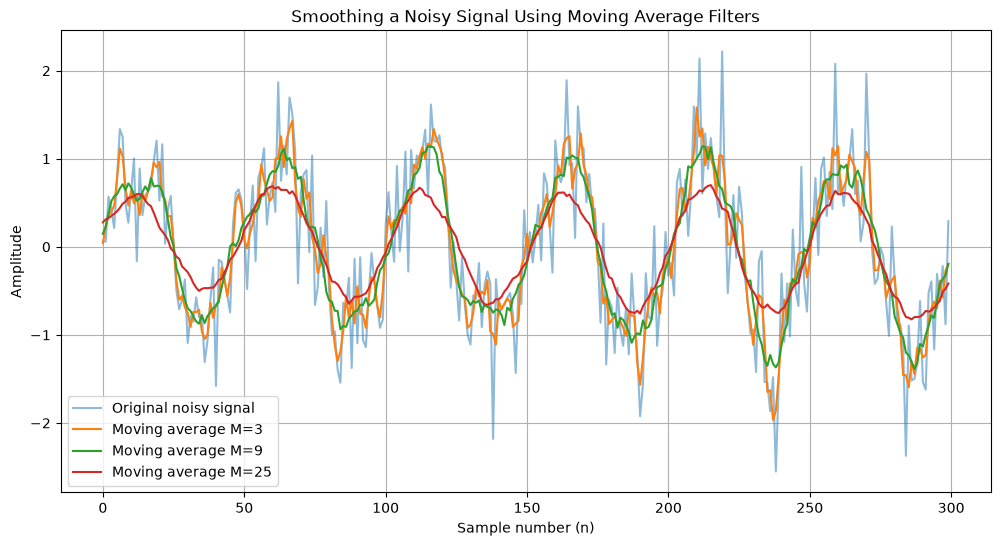

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate signal
n = np.arange(300)
rng = np.random.default_rng(0)

w = rng.standard_normal(300)

x = np.sin(2 * np.pi * n / 50) + 0.5 * w

# Moving average filter lengths
M_values = [3, 9, 25]

# Plot original noisy signal
plt.figure(figsize=(12, 6))
plt.plot(n, x, label="Original noisy signal", alpha=0.5)

# Apply moving average filters
for M in M_values:
    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")

    plt.plot(n, y, label=f"Moving average M={M}")

# Graph details
plt.title("Smoothing a Noisy Signal Using Moving Average Filters")
plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The moving average filters reduce noise in the original signal.

- M = 3: Provides slight noise reduction while preserving most signal details.
- M = 9: Provides better noise reduction with moderate smoothing.
- M = 25: Provides stronger noise reduction but causes more distortion and loss of signal details.

### Conclusion

Increasing the moving average filter length reduces noise, but it also increases signal distortion. Therefore, a suitable filter length should balance noise reduction and signal quality.

## Task 3.3 — Testing Linearity and Time-Invariance Numerically

### Objective
To test whether different systems satisfy the properties of linearity and time-invariance.

### Procedure
1. Generate two random input signals.
2. Test the linearity property using superposition.
3. Delay the input signal by five samples.
4. Compare the delayed output with the output of the delayed input.
5. Identify which systems are linear and time-invariant.

In [2]:
import numpy as np

# Generate random signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a, b = 2.0, -3.0

# Define systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test linearity and time-invariance
for name, T in systems.items():

    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


### Analysis and Explanation

**1. Squaring system:**

The system \(y(n)=x^2(n)\) is nonlinear because squaring does not satisfy the superposition property. It is time-invariant because delaying the input produces the same delayed output.

**2. Multiplication system:**

The system \(y(n)=nx(n)\) is linear because it satisfies superposition. However, it is not time-invariant because its output depends explicitly on the sample index \(n\).

**3. Moving average system:**

The moving average system is linear because it satisfies superposition. It is also time-invariant because delaying the input produces an equally delayed output.

### Conclusion

The moving average system is the only system among the three that is both linear and time-invariant (LTI).

## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

### Objective
To estimate the time delay between a transmitted signal and a received signal using cross-correlation.

### Procedure
1. Generate a random transmitted signal.
2. Create a delayed received signal with an actual delay of 37 samples.
3. Add Gaussian noise to the received signal.
4. Use cross-correlation to estimate the delay.
5. Increase the noise level and observe its effect on delay estimation.
6. Convert the estimated delay into distance using the speed of sound.

Actual delay: 37 samples
Estimated delay: 37 samples


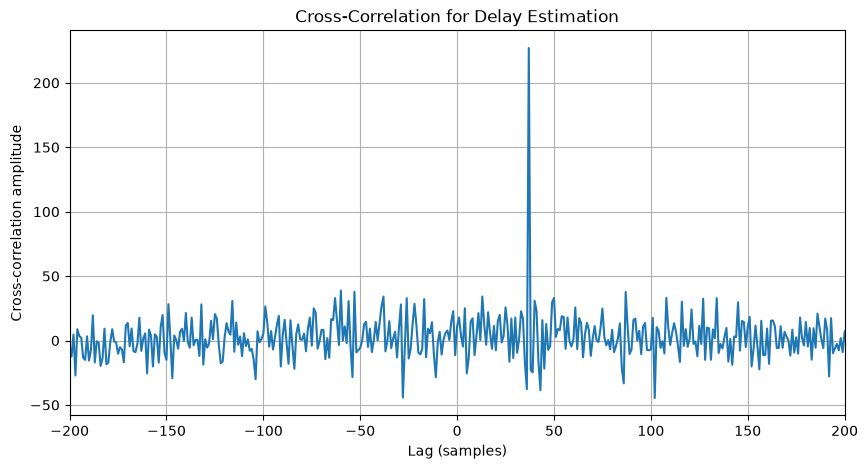

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Generate transmitted signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

# Create delayed received signal
true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] \
    + 0.5*rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(len(y), len(x), mode="full")

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("Actual delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Plot cross-correlation
plt.figure(figsize=(10, 5))
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.title("Cross-Correlation for Delay Estimation")
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-correlation amplitude")
plt.grid(True)
plt.show()

In [4]:
# Test different noise levels
noise_levels = [0.5, 1, 2, 4]

print("Delay estimation at different noise levels:")

for noise_std in noise_levels:

    rng = np.random.default_rng(1)

    y_noise = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] \
        + noise_std*rng.standard_normal(500)

    r_noise = signal.correlate(y_noise, x, mode="full")

    estimated = lags[np.argmax(r_noise)]

    print(f"Noise standard deviation = {noise_std}: "
          f"Estimated delay = {estimated} samples")

Delay estimation at different noise levels:
Noise standard deviation = 0.5: Estimated delay = 37 samples
Noise standard deviation = 1: Estimated delay = 0 samples
Noise standard deviation = 2: Estimated delay = 0 samples
Noise standard deviation = 4: Estimated delay = 0 samples


In [5]:
# Convert estimated delay into distance
speed_of_sound = 343

delay_seconds = estimated_delay / fs

distance = speed_of_sound * delay_seconds

print("Estimated delay:", estimated_delay, "samples")
print("Delay in seconds:", delay_seconds, "seconds")
print("Distance:", distance, "metres")

Estimated delay: 37 samples
Delay in seconds: 0.037 seconds
Distance: 12.690999999999999 metres


### Observation

Cross-correlation estimates the delay by finding the lag where the two signals are most similar.

The actual delay is 37 samples. At low noise levels, the estimated delay should be close to 37 samples. As the noise level increases, the correlation peak becomes less distinct, making delay estimation less reliable.

### Distance Calculation

The sampling frequency is 1000 Hz, and the estimated delay is 37 samples.

\[
t=\frac{37}{1000}=0.037\text{ seconds}
\]

Using the speed of sound of 343 m/s:

\[
d=343\times0.037=12.691\text{ metres}
\]

Therefore, the estimated one-way distance is 12.691 metres.

### Conclusion

Cross-correlation is useful for estimating delays between transmitted and received signals. However, high noise levels can reduce the accuracy of the estimated delay.

## Task 3.5 — Difference Equation

### Objective
To solve a difference equation using direct recursion and the Python `signal.lfilter()` function, and compare the results with the closed-form solution.

### Given Difference Equation

\[
y(n)-\frac{3}{4}y(n-1)+\frac{1}{8}y(n-2)
=x(n)+x(n-1)
\]

### Procedure
1. Calculate the impulse response using direct recursion.
2. Calculate the impulse response using `signal.lfilter()`.
3. Compare both results with the closed-form solution.
4. Calculate the step response.
5. Find and compare the final value with the DC gain \(H(1)\).

Direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed-form solution:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Direct recursion matches lfilter: True
lfilter matches closed-form: True


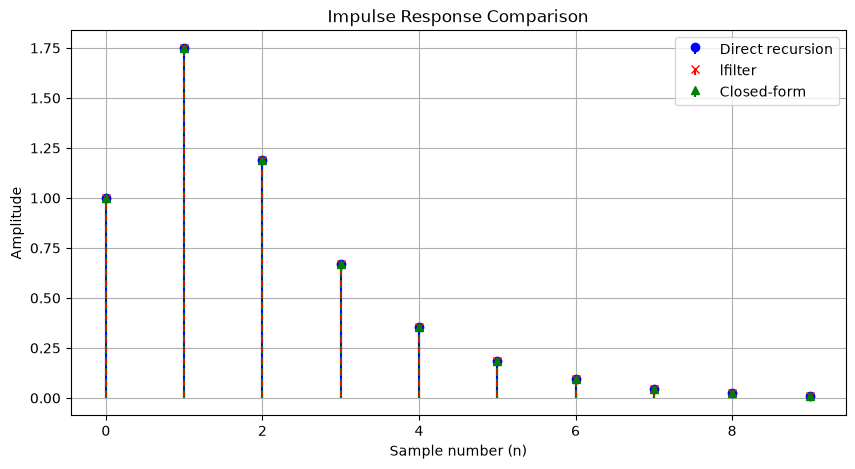

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Create impulse input
N = 10
impulse = np.zeros(N)
impulse[0] = 1

# Direct recursion
h_direct = np.zeros(N)

for n in range(N):
    x_n = impulse[n]
    x_n1 = impulse[n-1] if n >= 1 else 0

    y_n1 = h_direct[n-1] if n >= 1 else 0
    y_n2 = h_direct[n-2] if n >= 2 else 0

    h_direct[n] = x_n + x_n1 + 0.75*y_n1 - 0.125*y_n2

# Using lfilter
h_filter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

# Closed-form solution
n = np.arange(N)
h_formula = 6*(0.5**n) - 5*(0.25**n)

# Display results
print("Direct recursion:")
print(h_direct)

print("\nlfilter:")
print(h_filter)

print("\nClosed-form solution:")
print(h_formula)

print("\nDirect recursion matches lfilter:",
      np.allclose(h_direct, h_filter))

print("lfilter matches closed-form:",
      np.allclose(h_filter, h_formula))

# Plot impulse responses
plt.figure(figsize=(10, 5))

plt.stem(n, h_direct, linefmt='b-', markerfmt='bo',
         basefmt=' ', label="Direct recursion")

plt.stem(n, h_filter, linefmt='r--', markerfmt='rx',
         basefmt=' ', label="lfilter")

plt.stem(n, h_formula, linefmt='g:', markerfmt='g^',
         basefmt=' ', label="Closed-form")

plt.title("Impulse Response Comparison")
plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

Final step response value: 5.333333333333333
H(1): 5.333333333333333


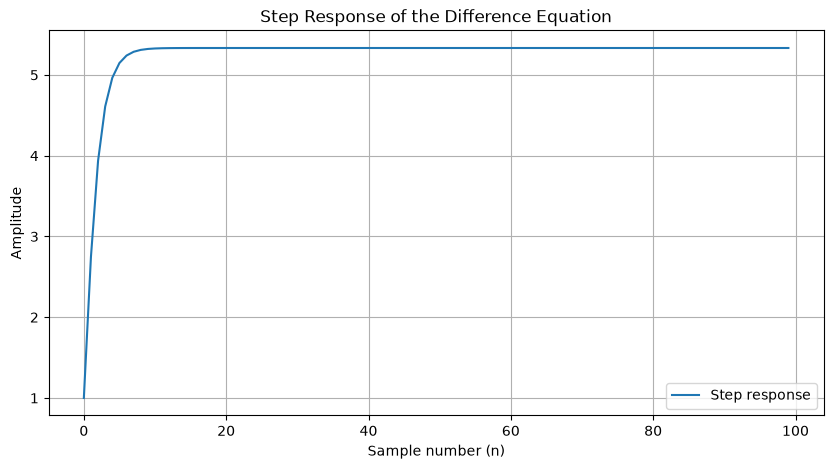

In [7]:
# Generate unit step input
step = np.ones(100)

# Calculate step response
step_response = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step
)

# Calculate final value
final_value = step_response[-1]

# Calculate H(1)
b = [1, 1]
a = [1, -0.75, 0.125]

H1 = sum(b) / sum(a)

print("Final step response value:", final_value)
print("H(1):", H1)

# Plot step response
plt.figure(figsize=(10, 5))
plt.plot(step_response, label="Step response")

plt.title("Step Response of the Difference Equation")
plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The impulse responses calculated using direct recursion, `signal.lfilter()` and the closed-form solution are equal.

The step response gradually approaches a final value of approximately 5.3333.

The calculated DC gain is:

\[
H(1)=\frac{\sum b}{\sum a}
=\frac{2}{0.375}=5.3333
\]

Therefore, the final step response value agrees with the calculated DC gain.

### Conclusion

The difference equation can be solved using direct recursion and `signal.lfilter()`. Both methods produce the same impulse response, confirming the correctness of the implementation.

## Analysis Questions

### Question 1

**Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths L and M?**

**Answer:**

`np.convolve` is faster because it is implemented using optimized compiled code, while our double-loop function uses Python loops, which have more execution overhead.

For two sequences of lengths L and M, the number of multiplications required for direct linear convolution is:

\[
\boxed{L\times M}
\]

Therefore, the computational complexity is \(O(LM)\).

### Question 2

**Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**

**Answer:**

The moving average system is the only LTI system among the three.

- \(y(n)=x^2(n)\): Nonlinear but time-invariant.
- \(y(n)=nx(n)\): Linear but time-varying.
- Moving average: Linear and time-invariant.

Yes, these properties could be predicted mathematically using the definitions of linearity and time-invariance without running the code.

### Question 3

**Give two engineering applications of cross-correlation in Tanzania.**

**Answer:**

1. **Water pipe leak detection:** Cross-correlation can compare acoustic signals recorded by sensors at different points along a water pipe to estimate the location of a leak.

2. **GPS navigation:** Cross-correlation is used in GPS receivers to identify satellite signals and estimate their arrival time, which helps determine the receiver's position.

### Question 4

**Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**

**Answer:**

The system is an Infinite Impulse Response (IIR) system because it uses feedback from previous output samples.

The system is stable because its impulse response gradually decreases towards zero as the sample number increases.

The closed-form impulse response is:

\[
h(n)=6(0.5)^n-5(0.25)^n
\]

Both exponential terms approach zero as \(n\) increases. Also, the poles are \(0.5\) and \(0.25\), which are inside the unit circle.

Therefore, the system is an IIR and stable system.

## AI-Use Statement

ChatGPT was used as an AI assistance tool to help understand convolution, correlation, difference equations, Python implementation and analysis of results. The code was executed and the results were checked in Jupyter Notebook.